# Bagian E1: Naïve Bayes untuk Data Tabular

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmad-fathan/Fundamentals-of-Data-Science/blob/main/Classification/bab-e1-naive-bayes-data-tabular.ipynb)

Bagian ini mempraktikkan materi Naïve Bayes pada data tabular, yaitu data berbentuk tabel dengan kolom berupa angka atau kategori. Kita akan:

1. memeriksa ulang hitungan contoh *Play Golf* dari modul dengan scikit-learn,
2. mengenal dataset Penguin dan melihat sebaran setiap fiturnya,
3. melatih model **Gaussian Naïve Bayes** dan melihat apa yang dipelajari model,
4. memprediksi seekor penguin baru, lalu mencocokkan hasilnya dengan perhitungan manual,
5. mengevaluasi model dengan akurasi, *classification report*, dan *confusion matrix*.

Contoh data teks (deteksi spam SMS) dibahas pada Bagian E2.

Jalankan cell secara berurutan dari atas ke bawah. Perkiraan waktu: 45 sampai 60 menit.

## E1.1 Mengimpor Library

In [1]:
%matplotlib inline
import numpy as np                      # komputasi numerik
import pandas as pd                     # tabel data (DataFrame)
import matplotlib.pyplot as plt         # visualisasi
from scipy.stats import norm            # distribusi normal, untuk perhitungan manual

from sklearn.model_selection import train_test_split          # membagi data latih dan uji
from sklearn.preprocessing import OrdinalEncoder              # mengubah kategori menjadi kode angka
from sklearn.naive_bayes import CategoricalNB, GaussianNB     # dua varian Naive Bayes
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

print("Library berhasil diimpor")

Library berhasil diimpor


## E1.2 Pemanasan: Memeriksa Hitungan Modul

Di modul, kita menghitung secara manual bahwa hari dengan cuaca *Sunny, Hot, Normal, False* diprediksi **Yes** dengan keyakinan sekitar 86,1 persen. Sebelum memakai data yang lebih besar, kita pastikan dulu bahwa scikit-learn memberikan hasil yang sama.

Semua fitur pada data ini berupa kategori, sehingga varian yang tepat adalah `CategoricalNB`. Varian ini menghitung likelihood dengan cara yang sama seperti tabel frekuensi di modul.

In [2]:
# dataset Play Golf, sama persis dengan Tabel 2 di modul
golf = pd.DataFrame([
    ["Rainy", "Hot", "High", "False", "Yes"], ["Rainy", "Hot", "High", "True", "No"],
    ["Overcast", "Hot", "High", "False", "Yes"], ["Sunny", "Mild", "High", "False", "No"],
    ["Sunny", "Cool", "Normal", "False", "Yes"], ["Sunny", "Cool", "Normal", "True", "No"],
    ["Overcast", "Cool", "Normal", "True", "Yes"], ["Rainy", "Mild", "High", "False", "No"],
    ["Rainy", "Cool", "Normal", "False", "Yes"], ["Sunny", "Mild", "Normal", "False", "Yes"],
    ["Rainy", "Mild", "Normal", "True", "Yes"], ["Overcast", "Mild", "High", "True", "Yes"],
    ["Overcast", "Hot", "Normal", "False", "Yes"], ["Sunny", "Mild", "High", "True", "No"],
], columns=["Outlook", "Temperature", "Humidity", "Wind", "Play"])

X_golf = golf.drop(columns="Play")
y_golf = golf["Play"]
print("Ukuran data:", golf.shape)
print(y_golf.value_counts())

Ukuran data: (14, 5)
Play
Yes    9
No     5
Name: count, dtype: int64


Model hanya dapat membaca angka, sehingga setiap kategori diubah menjadi kode angka dengan `OrdinalEncoder`. Misalnya, Overcast menjadi 0, Rainy menjadi 1, dan Sunny menjadi 2. Kode ini hanya label, bukan ukuran besar atau kecil.

In [3]:
encoder = OrdinalEncoder()
X_golf_kode = encoder.fit_transform(X_golf)

for kolom, kategori in zip(X_golf.columns, encoder.categories_):
    print(f"{kolom:12s}: {dict(zip(kategori, range(len(kategori))))}")

Outlook     : {'Overcast': 0, 'Rainy': 1, 'Sunny': 2}
Temperature : {'Cool': 0, 'Hot': 1, 'Mild': 2}
Humidity    : {'High': 0, 'Normal': 1}
Wind        : {'False': 0, 'True': 1}


Parameter `alpha` pada `CategoricalNB` adalah **Laplace smoothing**. Nilai `alpha=1` berarti menambahkan 1 pada setiap hasil hitungan, seperti di modul. Untuk mencocokkan hitungan manual *tanpa* smoothing, kita pakai `alpha` yang sangat kecil.

In [4]:
# tanpa smoothing (alpha hampir nol), seperti contoh lengkap di modul
model_golf = CategoricalNB(alpha=1e-10, force_alpha=True)
model_golf.fit(X_golf_kode, y_golf)

hari_ini = pd.DataFrame([["Sunny", "Hot", "Normal", "False"]], columns=X_golf.columns)
proba = model_golf.predict_proba(encoder.transform(hari_ini))[0]

print("Kelas            :", model_golf.classes_)
print("Probabilitas     :", proba.round(3))
print("Prediksi         :", model_golf.predict(encoder.transform(hari_ini))[0])

Kelas            : ['No' 'Yes']
Probabilitas     : [0.139 0.861]
Prediksi         : Yes


**Hasil yang diharapkan:** probabilitas Yes sekitar 0,861 dan No sekitar 0,139. Hasil ini sama dengan perhitungan manual pada Langkah 5 di modul.

Sekarang kita coba contoh latihan modul yang memakai Laplace smoothing, yaitu hari *Overcast, Cool, High, True*.

In [5]:
# dengan Laplace smoothing (alpha = 1)
model_golf_smooth = CategoricalNB(alpha=1.0)
model_golf_smooth.fit(X_golf_kode, y_golf)

hari_lain = pd.DataFrame([["Overcast", "Cool", "High", "True"]], columns=X_golf.columns)
proba = model_golf_smooth.predict_proba(encoder.transform(hari_lain))[0]
print("Probabilitas [No, Yes]:", proba.round(3))

Probabilitas [No, Yes]: [0.278 0.722]


**Hasil yang diharapkan:** Yes sekitar 0,722 dan No sekitar 0,278, sama dengan jawaban latihan di modul. Tanpa smoothing, kelas No akan bernilai nol karena Overcast tidak pernah muncul bersama No.

Data golf terlalu kecil untuk dibagi menjadi data latih dan data uji. Karena itu, mulai bagian berikutnya kita memakai dataset yang lebih besar.

## E1.3 Mengenal Dataset Penguin

Dataset Penguin berisi pengukuran 344 penguin dari tiga spesies, yaitu **Adelie**, **Chinstrap**, dan **Gentoo**, yang diamati di Kepulauan Palmer, Antartika. Tugas kita adalah memprediksi spesies seekor penguin dari ukuran tubuhnya.

Fitur yang kita pakai berupa angka (fitur kontinu):

- `bill_length_mm` = panjang paruh (mm)
- `bill_depth_mm` = tebal paruh (mm)
- `flipper_length_mm` = panjang sirip (mm)
- `body_mass_g` = berat badan (gram)

Kolom `island` dan `sex` berupa kategori. Kolom ini tidak kita pakai, karena Gaussian Naïve Bayes hanya menerima fitur angka.

In [6]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
penguin = pd.read_csv(url)

print("Ukuran data:", penguin.shape)
penguin.head()

Ukuran data: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [7]:
print("Jumlah nilai kosong per kolom:")
print(penguin.isna().sum())

Jumlah nilai kosong per kolom:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


Ada dua penguin yang seluruh ukurannya kosong. Baris tersebut kita buang, karena model tidak dapat belajar dari data yang tidak ada.

In [8]:
fitur = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

penguin = penguin.dropna(subset=fitur).reset_index(drop=True)
print("Ukuran data setelah dibersihkan:", penguin.shape)
print()
print(penguin["species"].value_counts())

Ukuran data setelah dibersihkan: (342, 7)

species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


Adelie adalah spesies paling banyak dan Chinstrap paling sedikit. Perbedaan jumlah ini nanti menjadi **prior** setiap kelas.

## E1.4 Melihat Sebaran Setiap Fitur

Gaussian Naïve Bayes mengasumsikan bahwa, di dalam setiap kelas, nilai sebuah fitur mengikuti distribusi normal (kurva lonceng). Histogram berikut memperlihatkan apakah asumsi ini masuk akal.

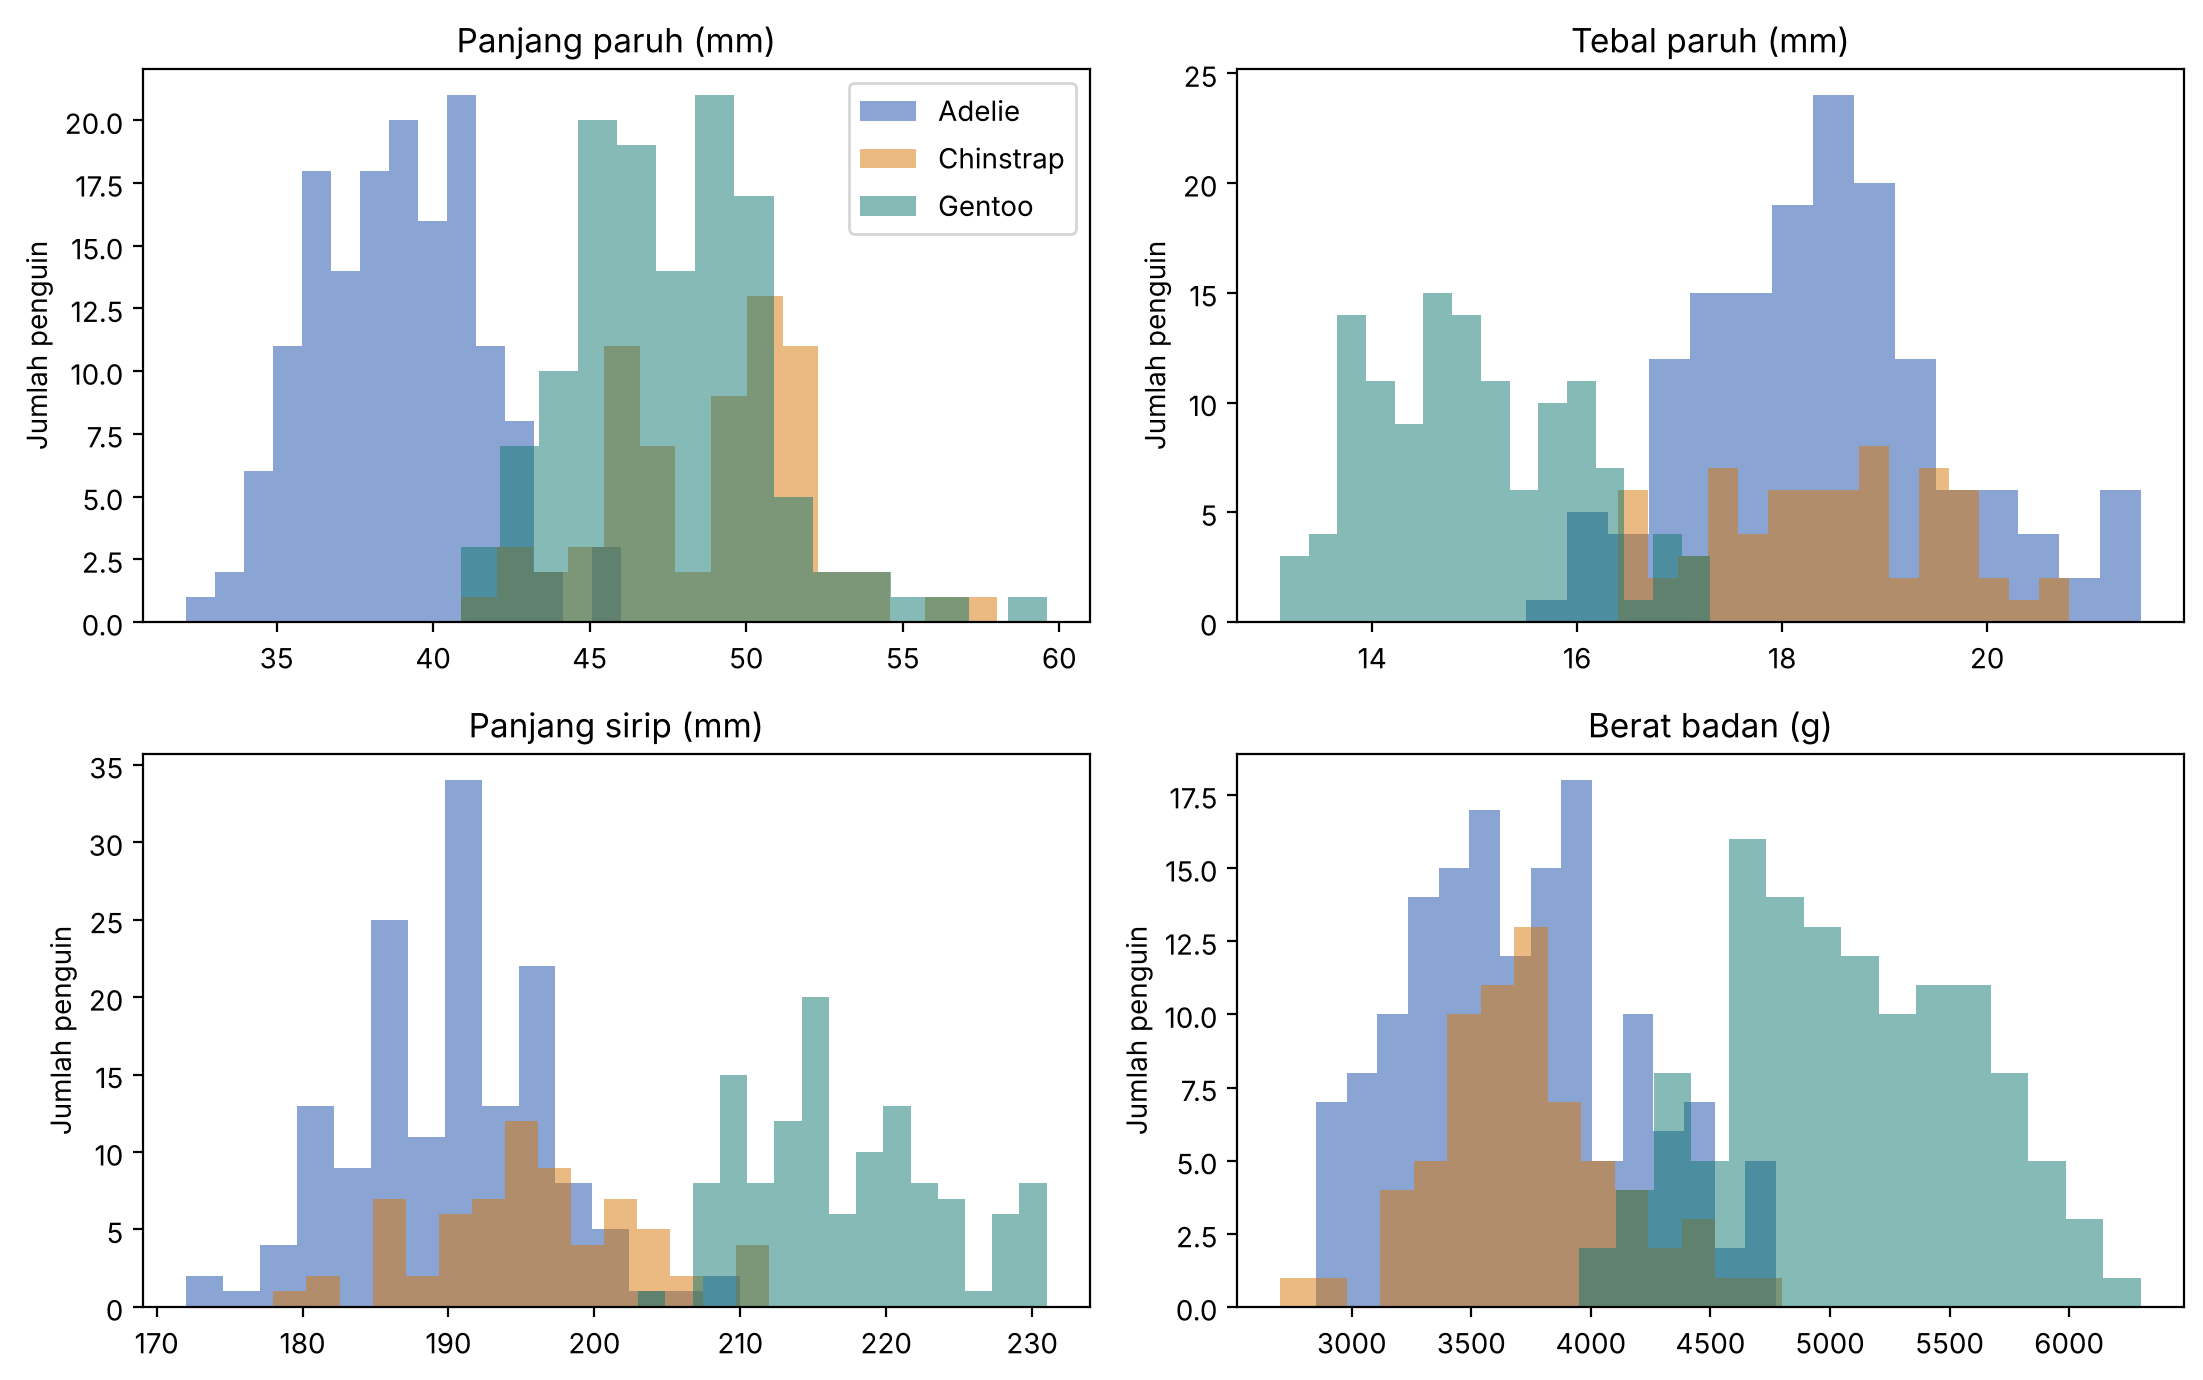

In [9]:
warna = {"Adelie": "#174CAA", "Chinstrap": "#D97706", "Gentoo": "#0F766E"}
nama_fitur = {"bill_length_mm": "Panjang paruh (mm)", "bill_depth_mm": "Tebal paruh (mm)",
              "flipper_length_mm": "Panjang sirip (mm)", "body_mass_g": "Berat badan (g)"}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, f in zip(axes.ravel(), fitur):
    for spesies, w in warna.items():
        nilai = penguin.loc[penguin["species"] == spesies, f]
        ax.hist(nilai, bins=15, alpha=0.5, color=w, label=spesies)
    ax.set_title(nama_fitur[f])
    ax.set_ylabel("Jumlah penguin")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

Ada tiga hal yang dapat dibaca dari grafik ini:

- **Setiap spesies membentuk satu "bukit".** Bentuknya cukup mirip kurva lonceng, sehingga asumsi distribusi normal masuk akal.
- **Gentoo mudah dikenali.** Siripnya paling panjang, badannya paling berat, dan paruhnya paling tipis.
- **Adelie dan Chinstrap mirip** pada panjang sirip dan berat badan. Keduanya baru jelas berbeda pada **panjang paruh**.

Karena tidak ada satu fitur yang mampu memisahkan ketiga spesies, model perlu menggabungkan keempat fitur. Penggabungan inilah yang dilakukan Naïve Bayes.

## E1.5 Membagi Data Latih dan Data Uji

Data dibagi menjadi 75 persen data latih dan 25 persen data uji. Parameter `stratify=y` menjaga agar proporsi ketiga spesies sama di kedua bagian, sedangkan `random_state=42` membuat hasil pembagian dapat diulang.

In [10]:
X = penguin[fitur]          # fitur: DataFrame 2 dimensi
y = penguin["species"]      # target: nama spesies

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

print("Data latih:", X_train.shape, "| data uji:", X_test.shape)

Data latih: (256, 4) | data uji: (86, 4)


## E1.6 Melatih Model Gaussian Naïve Bayes

Untuk fitur angka, likelihood dihitung dari kurva normal setiap kelas:

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\left(-\frac{(x_i-\mu_y)^2}{2\sigma_y^2}\right) \tag{1}$$

**Keterangan:**

- $P(x_i \mid y)$ = likelihood nilai fitur $x_i$ pada kelas $y$
- $x_i$ = nilai fitur ke-$i$, misalnya panjang sirip
- $\mu_y$ = rata-rata fitur tersebut pada kelas $y$
- $\sigma_y$ = standar deviasi fitur tersebut pada kelas $y$
- $\pi$ = konstanta pi, kira-kira 3,14159
- $\exp$ = fungsi eksponensial

Artinya, training cukup menghitung **rata-rata** dan **standar deviasi** setiap fitur untuk setiap spesies, ditambah **prior** setiap spesies.

In [11]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Kelas:", model.classes_)

Kelas: ['Adelie' 'Chinstrap' 'Gentoo']


Kita lihat apa saja yang dipelajari model. Mulai dari prior, yaitu proporsi setiap spesies pada data latih.

In [12]:
prior = pd.Series(model.class_prior_, index=model.classes_, name="prior")
prior.round(3)

Adelie       0.441
Chinstrap    0.199
Gentoo       0.359
Name: prior, dtype: float64

Berikutnya rata-rata ($\mu$) dan standar deviasi ($\sigma$) setiap fitur untuk setiap spesies. Atribut `theta_` menyimpan rata-rata, sedangkan `var_` menyimpan varians, sehingga standar deviasinya adalah akar dari `var_`.

In [13]:
rata_rata = pd.DataFrame(model.theta_, index=model.classes_, columns=fitur)
std_dev = pd.DataFrame(np.sqrt(model.var_), index=model.classes_, columns=fitur)

print("Rata-rata (mu):")
print(rata_rata.round(1))
print()
print("Standar deviasi (sigma):")
print(std_dev.round(1))

Rata-rata (mu):
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
Adelie               38.9           18.4              190.2       3723.2
Chinstrap            49.1           18.6              196.6       3762.3
Gentoo               47.7           14.9              216.8       5068.8

Standar deviasi (sigma):
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
Adelie                2.7            1.2                6.6        463.7
Chinstrap             3.5            1.1                7.1        399.2
Gentoo                3.1            0.9                6.5        506.4


Tabel ini sesuai dengan histogram tadi. Misalnya, rata-rata panjang sirip Gentoo sekitar 217 mm, jauh di atas Adelie dan Chinstrap yang sekitar 190 sampai 197 mm. Hanya angka-angka inilah yang disimpan model, dan tidak ada proses optimasi berulang.

## E1.7 Memprediksi Seekor Penguin Baru

Misalkan kita menemukan seekor penguin dengan ukuran berikut. Ukurannya sengaja dipilih di antara Adelie dan Chinstrap, supaya keputusannya tidak terlalu mudah.

In [14]:
penguin_baru = pd.DataFrame([{
    "bill_length_mm": 44.0,
    "bill_depth_mm": 18.0,
    "flipper_length_mm": 195.0,
    "body_mass_g": 3700.0,
}])

proba = model.predict_proba(penguin_baru)[0]
for spesies, p in zip(model.classes_, proba):
    print(f"{spesies:10s}: {p:.3f}")
print("Prediksi  :", model.predict(penguin_baru)[0])

Adelie    : 0.512
Chinstrap : 0.488
Gentoo    : 0.000
Prediksi  : Adelie


Grafik berikut memperlihatkan cara kerja Persamaan 1 untuk satu fitur, yaitu panjang sirip. Kurva digambar dari rata-rata dan standar deviasi yang dipelajari model. Garis putus-putus adalah panjang sirip penguin baru, dan titik pada setiap kurva adalah likelihood-nya.

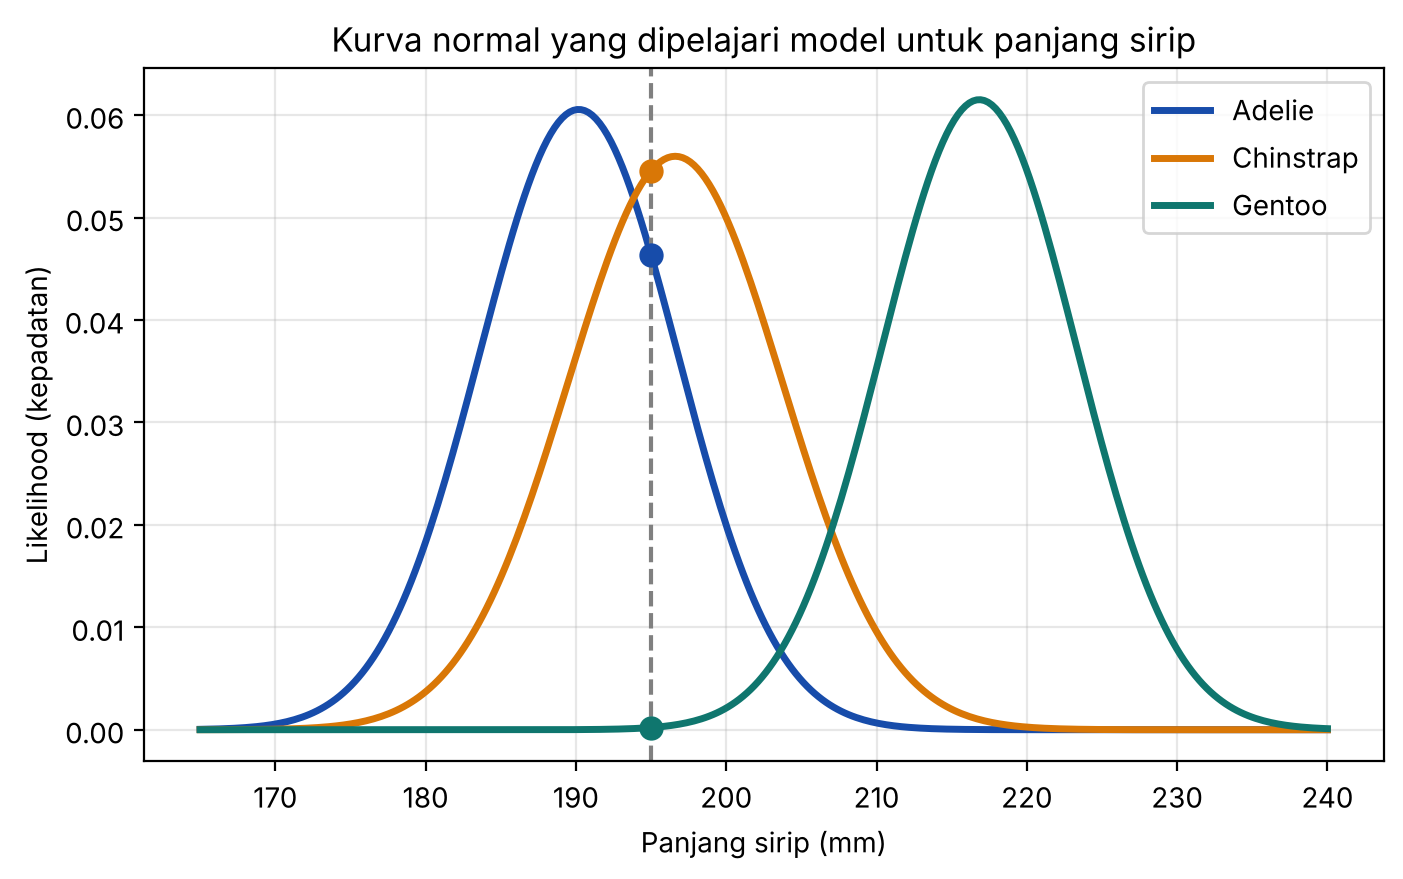

In [15]:
f = "flipper_length_mm"
x_baru = penguin_baru[f].iloc[0]
sumbu_x = np.linspace(165, 240, 300)

plt.figure(figsize=(8, 4.5))
for k, spesies in enumerate(model.classes_):
    mu, sigma = rata_rata.loc[spesies, f], std_dev.loc[spesies, f]
    plt.plot(sumbu_x, norm.pdf(sumbu_x, mu, sigma), color=warna[spesies], linewidth=2.5, label=spesies)
    plt.scatter([x_baru], [norm.pdf(x_baru, mu, sigma)], color=warna[spesies], s=60, zorder=3)
plt.axvline(x_baru, color="gray", linestyle="--")
plt.xlabel("Panjang sirip (mm)")
plt.ylabel("Likelihood (kepadatan)")
plt.title("Kurva normal yang dipelajari model untuk panjang sirip")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Pada panjang sirip 195 mm, kurva Adelie dan Chinstrap sama-sama tinggi, sedangkan kurva Gentoo hampir nol. Fitur ini saja sudah cukup untuk menyingkirkan Gentoo, tetapi belum cukup untuk membedakan Adelie dan Chinstrap. Fitur lain, terutama panjang paruh, ikut membantu.

### Mencocokkan dengan perhitungan manual

Model memakai aturan keputusan yang sama dengan modul:

$$\hat{y} = \arg\max_{y} \; P(y) \prod_{i=1}^{n} P(x_i \mid y) \tag{2}$$

**Keterangan:**

- $\hat{y}$ = spesies hasil prediksi
- $\arg\max_{y}$ = spesies $y$ yang menghasilkan nilai terbesar
- $P(y)$ = prior spesies $y$
- $P(x_i \mid y)$ = likelihood fitur ke-$i$ pada spesies $y$, dihitung dengan Persamaan 1
- $\prod_{i=1}^{n}$ = perkalian untuk keempat fitur
- $n$ = banyaknya fitur, yaitu 4

Kita hitung sendiri likelihood setiap fitur, kalikan dengan prior, lalu normalisasi. Hasilnya harus sama dengan `predict_proba`.

In [16]:
# likelihood setiap fitur untuk setiap spesies (Persamaan 1)
likelihood = pd.DataFrame(
    {f: [norm.pdf(penguin_baru[f].iloc[0], rata_rata.loc[s, f], std_dev.loc[s, f])
         for s in model.classes_] for f in fitur},
    index=model.classes_)

print("Likelihood setiap fitur:")
print(likelihood.map(lambda v: f"{v:.2e}"))

Likelihood setiap fitur:
          bill_length_mm bill_depth_mm flipper_length_mm body_mass_g
Adelie          2.54e-02      3.11e-01          4.64e-02    8.59e-04
Chinstrap       3.86e-02      3.19e-01          5.46e-02    9.87e-04
Gentoo          6.38e-02      1.34e-03          2.13e-04    2.04e-05


In [17]:
# skor = prior x hasil kali keempat likelihood (Persamaan 2)
skor = prior * likelihood.prod(axis=1)

# normalisasi: bagi dengan jumlah semua skor
manual = skor / skor.sum()

perbandingan = pd.DataFrame({"skor": skor.map(lambda v: f"{v:.3e}"),
                             "manual": manual.round(4),
                             "predict_proba": proba.round(4)})
perbandingan

,skor,manual,predict_proba
Adelie,1.386e-07,0.5116,0.5116
Chinstrap,1.323e-07,0.4884,0.4884
Gentoo,1.331e-13,0.0000,0.0000


**Hasil yang diharapkan:** kolom `manual` dan `predict_proba` bernilai sama. Jadi, `GaussianNB` hanya menjalankan Persamaan 1 dan Persamaan 2 untuk kita.

Perhatikan tabel likelihood di atas. Untuk **keempat** fitur, likelihood Chinstrap sedikit lebih tinggi daripada Adelie. Meskipun begitu, model memilih Adelie, walau hanya unggul tipis (sekitar 51 berbanding 49 persen). Penyebabnya adalah **prior**: Adelie jauh lebih banyak di data latih (0,441) daripada Chinstrap (0,199). Contoh ini memperlihatkan peran prior dalam Teorema Bayes, yaitu keyakinan awal yang ikut menentukan keputusan ketika bukti dari fitur hampir seimbang.

Skor sebelum normalisasi sangat kecil karena merupakan hasil kali empat likelihood. Pada data dengan banyak fitur, angka ini bisa terlalu kecil untuk disimpan komputer. Karena itu scikit-learn sebenarnya menjumlahkan **logaritma** likelihood, bukan mengalikannya. Hasil akhirnya tetap sama.

## E1.8 Mengevaluasi Model

Sekarang kita ukur kinerja model pada data uji, yaitu data yang tidak dilihat model saat training.

In [18]:
y_pred = model.predict(X_test)

print(f"Akurasi data uji: {accuracy_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred, digits=3))

Akurasi data uji: 0.988

              precision    recall  f1-score   support

      Adelie      0.974     1.000     0.987        38
   Chinstrap      1.000     0.941     0.970        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          0.988        86
   macro avg      0.991     0.980     0.986        86
weighted avg      0.989     0.988     0.988        86



Akurasi sekitar 0,99 berarti hampir semua penguin di data uji ditebak dengan benar. Untuk mengetahui di mana kesalahannya, kita lihat *confusion matrix*. Baris menunjukkan spesies sebenarnya dan kolom menunjukkan hasil prediksi.

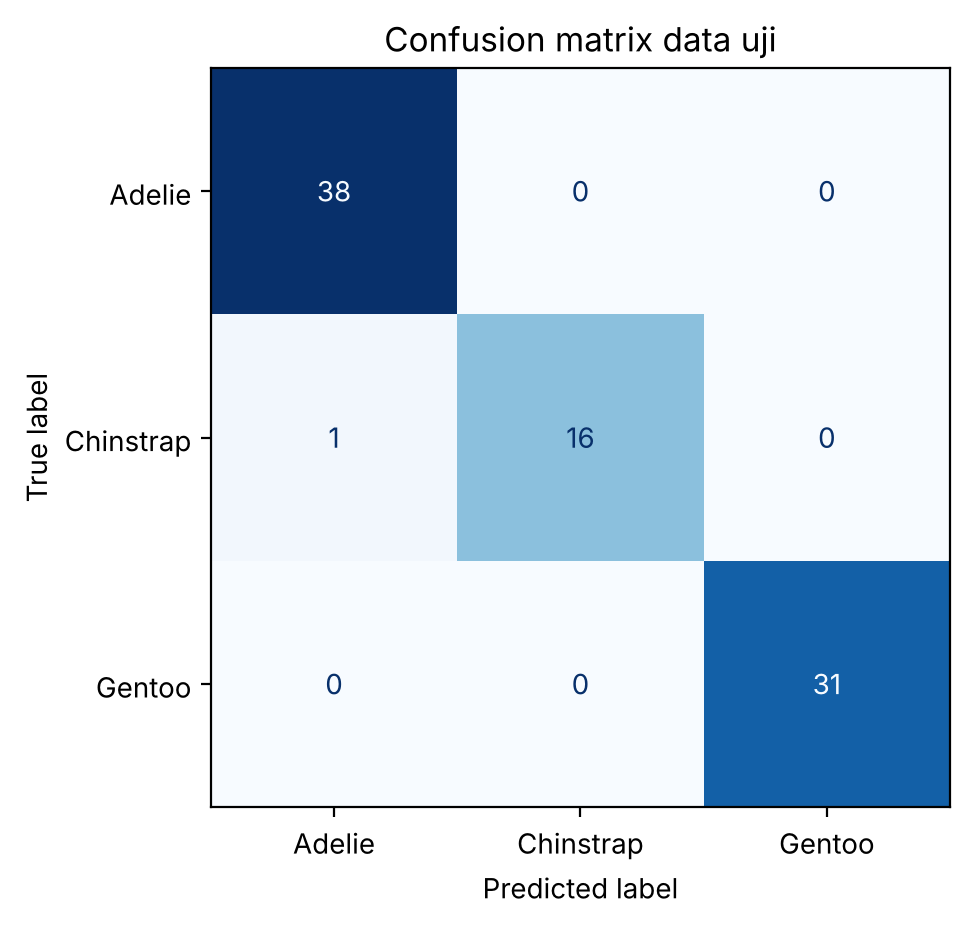

In [19]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(cm, display_labels=model.classes_)
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix data uji")
plt.show()

Angka di diagonal adalah prediksi yang benar. Satu-satunya kesalahan adalah seekor Chinstrap yang ditebak sebagai Adelie. Hal ini sesuai dengan histogram di E1.4: kedua spesies itu memang mirip pada sebagian besar ukuran, sedangkan Gentoo sangat berbeda sehingga tidak pernah salah ditebak.

## E1.9 Latihan

Kerjakan latihan berikut di cell kosong yang tersedia. Gunakan hanya teknik yang sudah dibahas di notebook ini.

**Latihan 1.** Latih `GaussianNB` yang hanya memakai **satu** fitur, yaitu `flipper_length_mm`, dengan pembagian data yang sama. Hitung akurasinya pada data uji, lalu bandingkan dengan model empat fitur.

*Hasil yang diharapkan:* akurasi sekitar 0,80, lebih rendah daripada model empat fitur. Jelaskan alasannya dengan melihat grafik kurva normal di E1.7.

In [20]:
# Latihan 1


**Latihan 2.** Coba setiap fitur satu per satu, seperti Latihan 1, untuk keempat fitur. Fitur mana yang paling berguna jika dipakai sendirian? Apakah jawaban Anda sesuai dengan histogram di E1.4?

*Hasil yang diharapkan:* sebuah tabel kecil berisi nama fitur dan akurasinya.

In [21]:
# Latihan 2


**Latihan 3.** Buat seekor penguin baru dengan ukuran pilihan Anda sendiri. Prediksi spesiesnya beserta probabilitasnya, lalu cocokkan hasilnya dengan perhitungan manual seperti di E1.7.

*Hasil yang diharapkan:* probabilitas hasil perhitungan manual sama dengan hasil `predict_proba`.

In [22]:
# Latihan 3


Selanjutnya, **Bagian E2** menerapkan Naïve Bayes pada data teks untuk mendeteksi SMS spam.